# DS1 clustering

Checks whether DS1 patients form natural groups without using the diagnosis, and whether those groups match CKD vs not CKD. Four methods are used: k-means, hierarchical, Gaussian mixture (fitted with the EM algorithm) and DBSCAN. Input is the preprocessed training set from `Data_Preprocessing.ipynb` (`3_preprocessed_data/`), so all features are imputed, scaled and encoded 0/1.

**Methods**

| Method | Idea | Setting |
|---|---|---|
| k-means | Groups around a centre | k from 2 to 8, 10 restarts |
| Hierarchical (Ward) | Tree of merges | Dendrogram, k from 2 to 8 |
| Gaussian mixture (EM) | Soft, oval groups | Diagonal covariance, k from 2 to 8 |
| DBSCAN | Dense regions, outliers as noise | min_samples 5, eps from percentiles of the 4th-nearest-neighbour distance |

**Checks**

| Check | Uses the labels | Meaning |
|---|---|---|
| Elbow (k-means inertia) | no | Where adding clusters stops helping |
| Silhouette | no | How well each patient fits its cluster: 1 is perfect, 0 is on a border |
| Adjusted Rand index (ARI) | yes, after fitting | Match between clusters and CKD vs not CKD: 1 is a perfect match, 0 is random |

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

root = Path.cwd()
while not (root / "configs" / "config.json").is_file():
    root = root.parent

config = json.loads((root / "configs" / "config.json").read_text())
ds = config["datasets"]["list"]["DS1"]
base = (root / "configs" / config["paths"]["datasets_dir"] / ds["folder"]).resolve()
RANDOM_STATE = config["training"]["random_state"]

## 1. Load the preprocessed training set

In [2]:
train = pd.read_csv(base / ds["files"]["preprocessed"]["train"])
X = train.drop(columns=["class"])
y = train["class"].map({"notckd": 0, "ckd": 1})
short = ["Not CKD", "CKD"]

print(X.shape)

(320, 30)


**Observation:**
- Target is only used to compare with the clusters, never to fit them
- All 320 training rows are used, as the dataset is small enough for every method

## 2. Look for structure with PCA

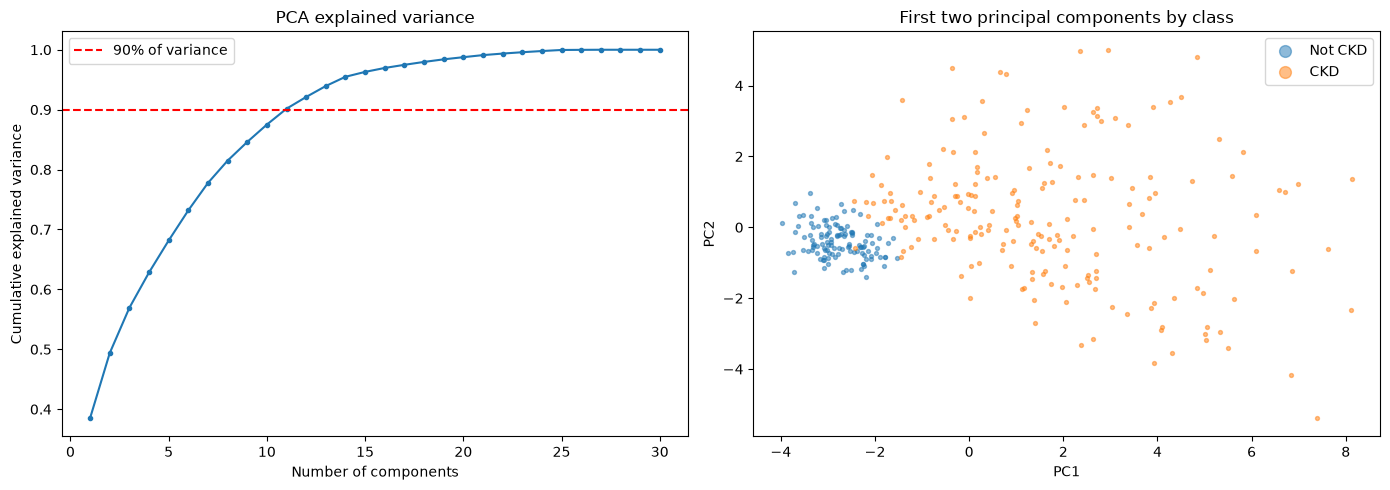

Components for 90%: 11 of 30


In [3]:
pca = PCA(random_state=RANDOM_STATE).fit(X)
cum = np.cumsum(pca.explained_variance_ratio_)
pcs = pca.transform(X)[:, :2]


def pca_plot(ax, groups, names, title):
    for g, name in zip(np.unique(groups), names):
        ax.scatter(pcs[groups == g, 0], pcs[groups == g, 1], s=8, alpha=0.5, label=name)
    ax.set(xlabel="PC1", ylabel="PC2", title=title)
    ax.legend(markerscale=3)


fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(range(1, len(cum) + 1), cum, marker=".")
axes[0].axhline(0.9, color="red", linestyle="--", label="90% of variance")
axes[0].set(xlabel="Number of components", ylabel="Cumulative explained variance", title="PCA explained variance")
axes[0].legend()
pca_plot(axes[1], y.values, short, "First two principal components by class")
fig.tight_layout()
plt.show()
print("Components for 90%:", (cum < 0.9).sum() + 1, "of", X.shape[1])

**Observation:**
- 11 of 30 components are needed for 90% of the variance
- In the first two components, not-CKD patients form a tight group, while CKD patients are spread widely

## 3. Hierarchical clustering

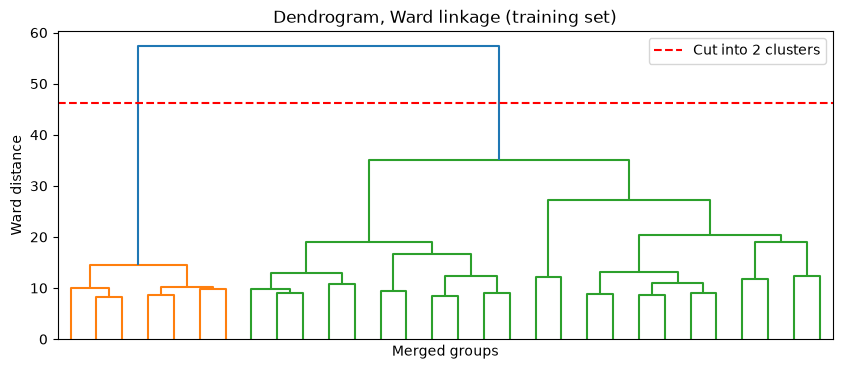

In [4]:
Z = linkage(X, method="ward")
cut = (Z[-1, 2] + Z[-2, 2]) / 2

plt.figure(figsize=(10, 4))
dendrogram(Z, truncate_mode="lastp", p=30, no_labels=True, color_threshold=cut)
plt.axhline(cut, color="red", linestyle="--", label="Cut into 2 clusters")
plt.xlabel("Merged groups")
plt.ylabel("Ward distance")
plt.title("Dendrogram, Ward linkage (training set)")
plt.legend()
plt.show()

**Observation:**
- One long gap at the top of the dendrogram, so the data splits clearly into 2 groups

## 4. Choose the number of clusters

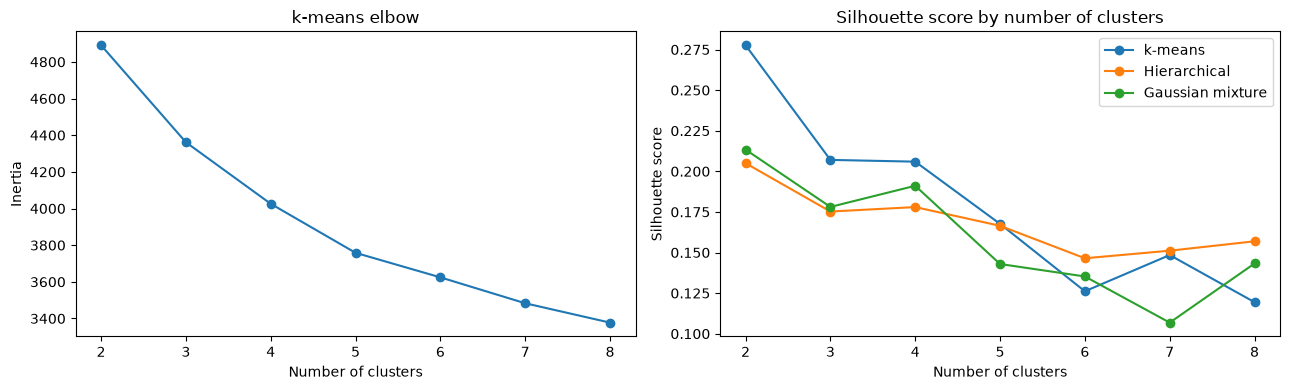

,k-means,Hierarchical,Gaussian mixture
2,0.278,0.205,0.213
3,0.207,0.175,0.178
4,0.206,0.178,0.191
5,0.168,0.166,0.143
6,0.126,0.146,0.135
7,0.148,0.151,0.107
8,0.119,0.157,0.143


In [5]:
make = {
    "k-means": lambda k: KMeans(k, n_init=10, random_state=RANDOM_STATE),
    "Hierarchical": lambda k: AgglomerativeClustering(k, linkage="ward"),
    "Gaussian mixture": lambda k: GaussianMixture(k, covariance_type="diag", random_state=RANDOM_STATE),
}
ks = range(2, 9)
fits = {(m, k): make[m](k).fit(X) for m in make for k in ks}
labels = {key: f.labels_ if hasattr(f, "labels_") else f.predict(X) for key, f in fits.items()}

sil = pd.DataFrame({m: [silhouette_score(X, labels[m, k]) for k in ks] for m in make}, index=ks)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(list(ks), [fits["k-means", k].inertia_ for k in ks], marker="o")
axes[0].set(xlabel="Number of clusters", ylabel="Inertia", title="k-means elbow")
sil.plot(marker="o", ax=axes[1])
axes[1].set(xlabel="Number of clusters", ylabel="Silhouette score", title="Silhouette score by number of clusters")
fig.tight_layout()
plt.show()
display(sil.round(3))

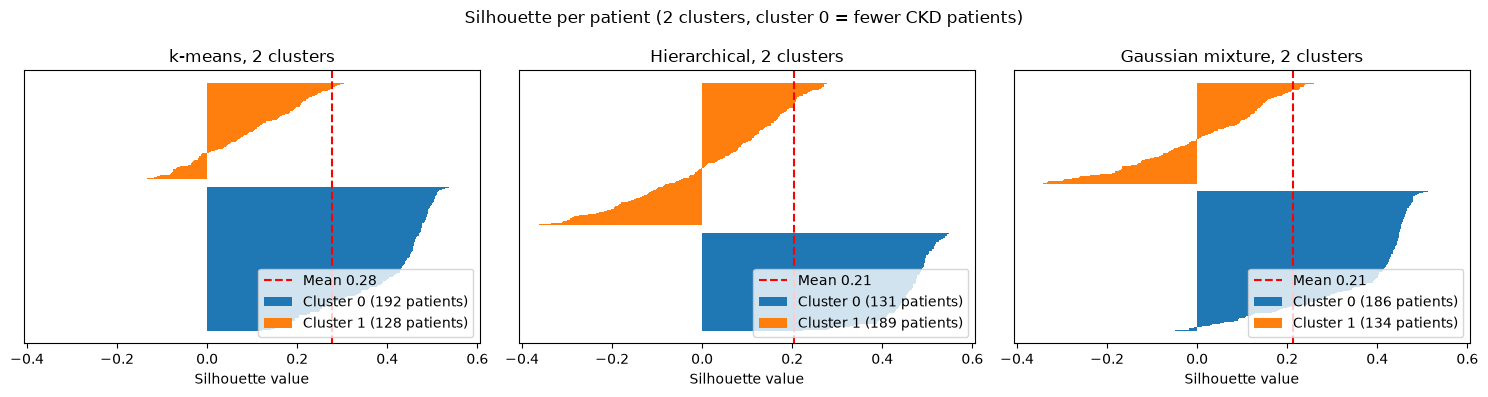

In [6]:
two = {m: labels[m, 2] for m in make}
two = {m: l if y[l == 0].mean() < y[l == 1].mean() else 1 - l for m, l in two.items()}


def silhouette_plot(ax, l, title):
    s = silhouette_samples(X, l)
    start = 0
    for c in np.unique(l):
        vals = np.sort(s[l == c])
        ax.barh(range(start, start + len(vals)), vals, height=1, label=f"Cluster {c} ({len(vals)} patients)")
        start += len(vals) + 10
    ax.axvline(s.mean(), color="red", linestyle="--", label=f"Mean {s.mean():.2f}")
    ax.set(xlabel="Silhouette value", yticks=[], title=title)
    ax.legend(loc="lower right")


fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
for ax, (m, l) in zip(axes, two.items()):
    silhouette_plot(ax, l, f"{m}, 2 clusters")
fig.suptitle("Silhouette per patient (2 clusters, cluster 0 = fewer CKD patients)")
fig.tight_layout()
plt.show()

**Observation:**
- The k-means elbow curve has no sharp bend
- Silhouette is highest at 2 or 3 clusters for every method (up to 0.28)
- With 2 clusters, the silhouette plots show one tight cluster and one wide cluster with many patients near 0, so the groups overlap

## 5. DBSCAN

,eps,Clusters,Noise %,Adjusted Rand index
eps percentile,,,,
10,2.07,5.0,77.50,0.39
25,2.33,1.0,63.12,0.68
50,2.97,1.0,39.69,0.29
75,3.81,1.0,16.88,-0.02
90,4.77,1.0,4.69,-0.03


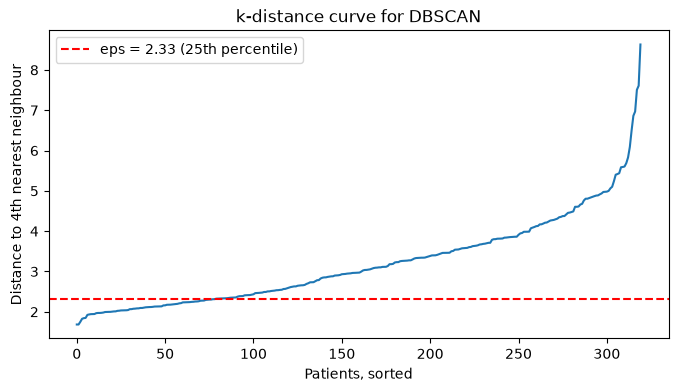

Distance to 4th nearest neighbour: 1.68 to 8.63


In [7]:
dist = np.sort(NearestNeighbors(n_neighbors=5).fit(X).kneighbors(X)[0][:, -1])
percentiles = [10, 25, 50, 75, 90]
chosen = 25

rows = {}
for p in percentiles:
    eps = np.percentile(dist, p)
    l = DBSCAN(eps=eps, min_samples=5).fit_predict(X)
    rows[p] = {"eps": eps, "Clusters": l.max() + 1, "Noise %": (l == -1).mean() * 100,
               "Adjusted Rand index": adjusted_rand_score(y, l)}
display(pd.DataFrame(rows).T.round(2).rename_axis("eps percentile"))

plt.figure(figsize=(8, 4))
plt.plot(dist)
plt.axhline(np.percentile(dist, chosen), color="red", linestyle="--", label=f"eps = {np.percentile(dist, chosen):.2f} ({chosen}th percentile)")
plt.xlabel("Patients, sorted")
plt.ylabel("Distance to 4th nearest neighbour")
plt.title("k-distance curve for DBSCAN")
plt.legend()
plt.show()
print("Distance to 4th nearest neighbour:", round(dist.min(), 2), "to", round(dist.max(), 2))

**Observation:**
- Distances to the 4th nearest neighbour (5 points with the patient itself, as min_samples counts it) vary a lot (1.7 to 8.6), and the curve rises steadily without a clear knee
- At the 25th percentile eps, DBSCAN finds a dense group of healthy patients and marks most CKD patients as noise (Adjusted Rand index 0.68), as CKD patients vary much more
- Larger eps merges everyone into one cluster, so DBSCAN cannot separate the two classes here

## 6. Compare clusters with the class

,Adjusted Rand index,Silhouette
k-means,0.299,0.278
Hierarchical,0.867,0.205
Gaussian mixture,0.342,0.213


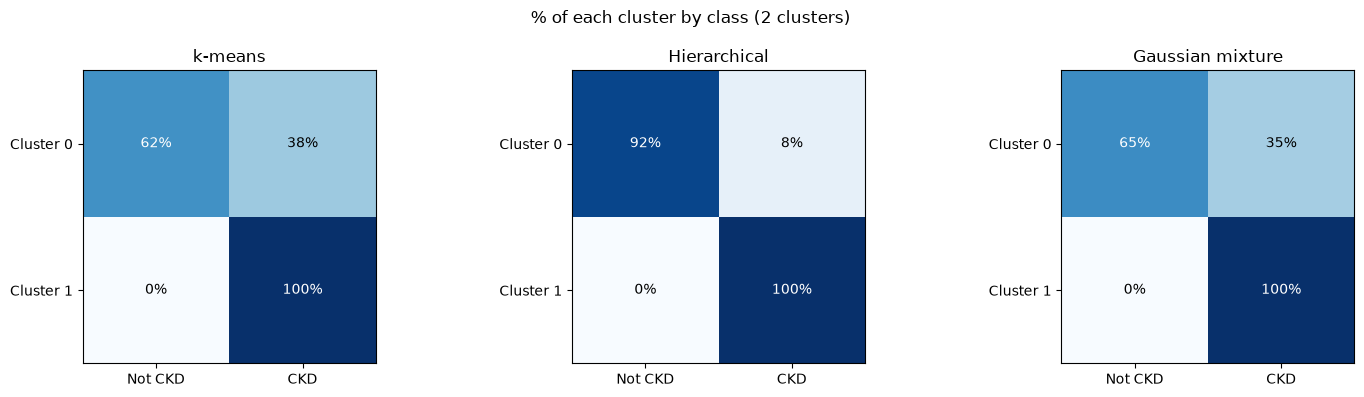

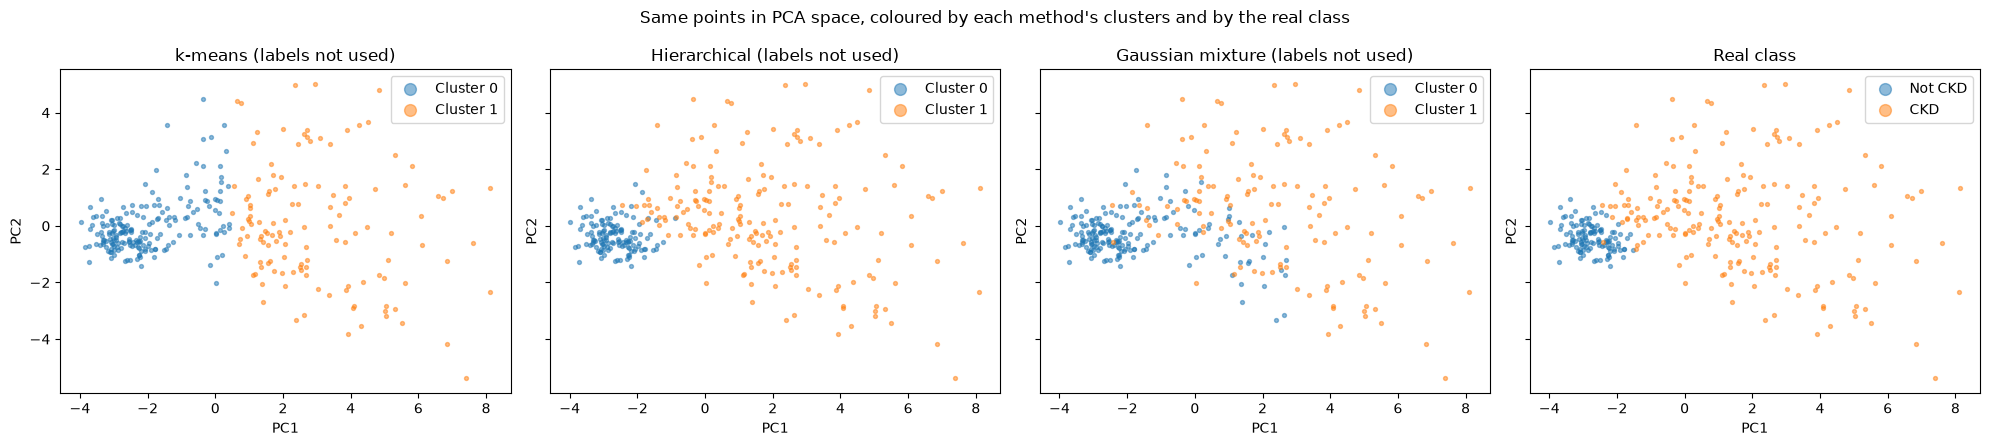

In [8]:
display(pd.DataFrame({
    "Adjusted Rand index": [adjusted_rand_score(y, l) for l in two.values()],
    "Silhouette": [silhouette_score(X, l) for l in two.values()],
}, index=list(two)).round(3))


def heatmap(ax, l, title):
    mix = pd.crosstab(l, y, normalize="index").mul(100)
    ax.imshow(mix, cmap="Blues", vmin=0, vmax=100)
    ax.set(xticks=range(2), xticklabels=short, yticks=range(len(mix)), yticklabels=[f"Cluster {i}" for i in mix.index], title=title)
    for i in range(len(mix)):
        for j in range(2):
            ax.text(j, i, f"{mix.iloc[i, j]:.0f}%", ha="center", va="center", color="white" if mix.iloc[i, j] > 50 else "black")


fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (m, l) in zip(axes, two.items()):
    heatmap(ax, l, m)
fig.suptitle("% of each cluster by class (2 clusters)")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), sharex=True, sharey=True)
for ax, (m, l) in zip(axes, two.items()):
    pca_plot(ax, l, ["Cluster 0", "Cluster 1"], f"{m} (labels not used)")
pca_plot(axes[3], y.values, short, "Real class")
fig.suptitle("Same points in PCA space, coloured by each method's clusters and by the real class")
fig.tight_layout()
plt.show()

**Observation:**
- 2 clusters are used to match CKD vs not CKD, and cluster 0 is always the one with fewer CKD patients
- Hierarchical clustering almost exactly recovers the diagnosis (Adjusted Rand index 0.87) without seeing the labels
- k-means and the Gaussian mixture put all healthy patients in one cluster but also pull in many CKD patients (38% and 35% of that cluster), so they split by severity rather than diagnosis
- Silhouette alone would have picked k-means (0.28), which is why the clusters are also checked against the labels

## 7. Clusters vs real labels: profile in original units

,Patients,CKD %,Serum creatinine,Blood urea,Hemoglobin,Packed cell volume,Specific gravity,Albumin,Hypertension %
Cluster,,,,,,,,,
0,131,8.4,0.90,32.0,15.0,45.0,1.02,0.0,0.76
1,189,100.0,2.25,54.0,10.9,33.0,1.01,2.0,58.20


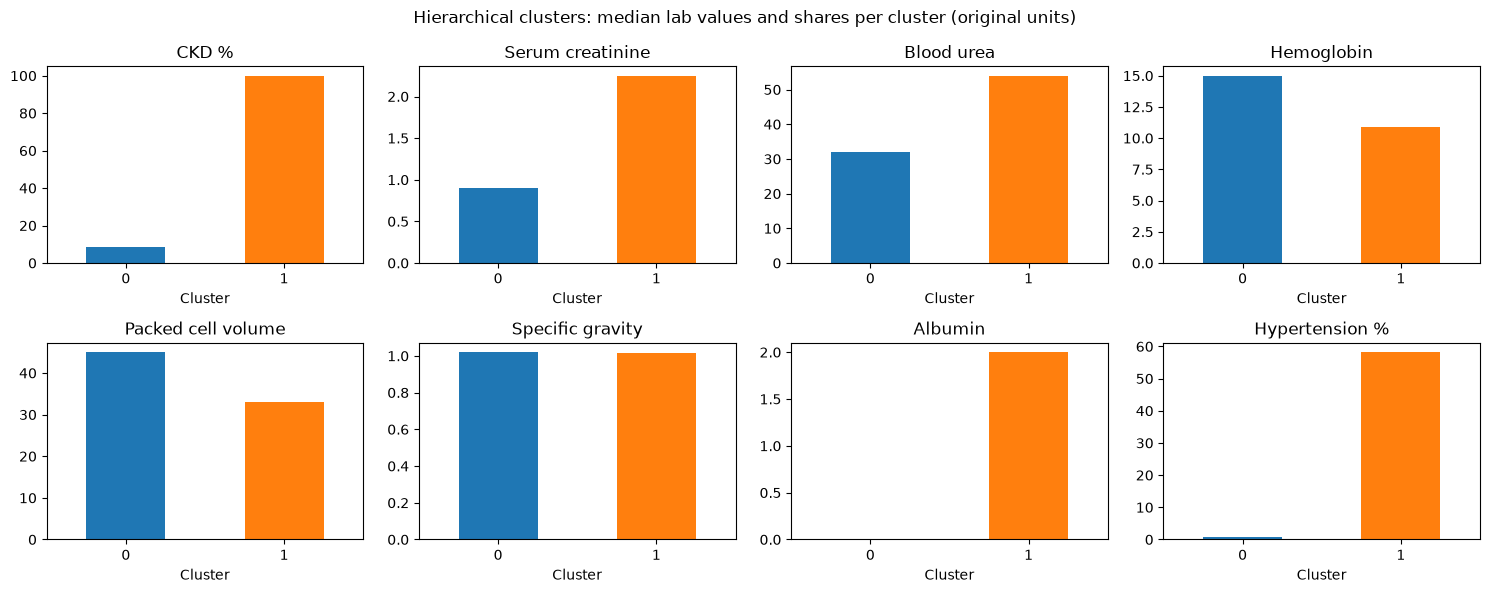

In [9]:
full = pd.read_csv(base / ds["files"]["feature_engineered"][0], na_values=ds["na_values"] or None)
raw, _ = train_test_split(full, test_size=config["training"]["test_size"], random_state=config["training"]["random_state"], stratify=full["class"])
raw = raw.reset_index(drop=True)
h = two["Hierarchical"]
key = {"sc": "Serum creatinine", "bu": "Blood urea", "hemo": "Hemoglobin", "pcv": "Packed cell volume", "sg": "Specific gravity", "al": "Albumin"}

profile = raw[list(key)].groupby(h).median().rename(columns=key)
profile.insert(0, "Patients", pd.Series(h).value_counts().sort_index())
profile.insert(1, "CKD %", y.groupby(h).mean().mul(100))
profile["Hypertension %"] = raw["htn"].eq("yes").groupby(h).mean().mul(100)
profile = profile.rename_axis("Cluster")
display(profile.round(2))

fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, col in zip(axes.flat, profile.columns.drop("Patients")):
    profile[col].plot(kind="bar", ax=ax, color=["C0", "C1"], rot=0, title=col)
fig.suptitle("Hierarchical clusters: median lab values and shares per cluster (original units)")
fig.tight_layout()
plt.show()

## 8. Check different feature groups

,Features,Adjusted Rand index
All features,30,0.867
Numeric only,20,0.480
"Continuous only (no graded sg, al, su)",17,0.429
0/1 features only,10,0.743


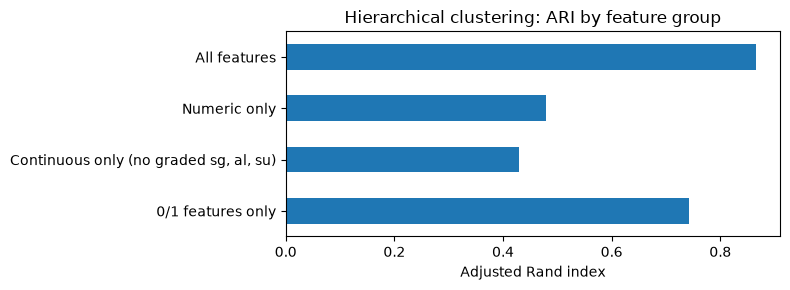

In [10]:
binary = [c for c in X.columns if X[c].nunique() == 2]
graded = ["sg", "al", "su"]
groups = {
    "All features": list(X.columns),
    "Numeric only": [c for c in X.columns if c not in binary],
    "Continuous only (no graded sg, al, su)": [c for c in X.columns if c not in binary + graded],
    "0/1 features only": binary,
}
ari = pd.DataFrame({
    "Features": [len(cols) for cols in groups.values()],
    "Adjusted Rand index": [adjusted_rand_score(y, AgglomerativeClustering(2, linkage="ward").fit_predict(X[cols])) for cols in groups.values()],
}, index=list(groups))
display(ari.round(3))

ari["Adjusted Rand index"].plot(kind="barh", figsize=(8, 3), title="Hierarchical clustering: ARI by feature group")
plt.xlabel("Adjusted Rand index")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()